U Food MArketing Analysis

In [1103]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

food = pd.read_csv("u_food_marketing.csv")

pd.set_option("display.max_columns", 2300)
pd.set_option("display.max_rows", 50)

food.info()

<class 'pandas.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Income                2205 non-null   float64
 1   Kidhome               2205 non-null   int64  
 2   Teenhome              2205 non-null   int64  
 3   Recency               2205 non-null   int64  
 4   MntWines              2205 non-null   int64  
 5   MntFruits             2205 non-null   int64  
 6   MntMeatProducts       2205 non-null   int64  
 7   MntFishProducts       2205 non-null   int64  
 8   MntSweetProducts      2205 non-null   int64  
 9   MntGoldProds          2205 non-null   int64  
 10  NumDealsPurchases     2205 non-null   int64  
 11  NumWebPurchases       2205 non-null   int64  
 12  NumCatalogPurchases   2205 non-null   int64  
 13  NumStorePurchases     2205 non-null   int64  
 14  NumWebVisitsMonth     2205 non-null   int64  
 15  AcceptedCmp3          2205 non-n

In [1104]:
food.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Customer_Days,marital_Divorced,marital_Married,marital_Single,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,63,2822,0,0,1,0,0,0,0,1,0,0,1529,1441,0
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,66,2272,0,0,1,0,0,0,0,1,0,0,21,15,0
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,55,2471,0,0,0,1,0,0,0,1,0,0,734,692,0
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,36,2298,0,0,0,1,0,0,0,1,0,0,48,43,0
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,39,2320,0,1,0,0,0,0,0,0,0,1,407,392,0


Data Cleaning

In [ ]:
# Check for duplicate rows in the dataset

food.duplicated().sum() # Remove duplicate rows, 184 in total
food.drop_duplicates(keep= False, inplace=True)
food.duplicated().sum() # Verify that duplicates have been removed, should be 0

np.int64(0)

In [ ]:
# Create a new column for the total number of children in the household

food['Total_Children'] = food[['Kidhome', 'Teenhome']].sum(axis=1)

food.head() # Display the first few rows to verify the new column has been added

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Customer_Days,marital_Divorced,marital_Married,marital_Single,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Total_Children
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,63,2822,0,0,1,0,0,0,0,1,0,0,1529,1441,0,0
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,66,2272,0,0,1,0,0,0,0,1,0,0,21,15,0,2
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,55,2471,0,0,0,1,0,0,0,1,0,0,734,692,0,0
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,36,2298,0,0,0,1,0,0,0,1,0,0,48,43,0,1
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,39,2320,0,1,0,0,0,0,0,0,0,1,407,392,0,1


In [ ]:
# Encode marital status columns and create a combined marital status code and label

food['marital_Divorced'] = food[['marital_Divorced']].replace({1:5, 0:0})
food['marital_Married'] = food[['marital_Married']].replace({1:4, 0:0})
food['marital_Single'] = food[['marital_Single']].replace({1:3, 0:0})
food['marital_Together'] = food[['marital_Together']].replace({1:2, 0:0})
food['marital_Widow'] = food[['marital_Widow']].replace({1:1, 0:0})

food['Marital_Status'] = food[['marital_Divorced', 'marital_Married', 'marital_Single', 'marital_Together', 'marital_Widow']].sum(axis=1) # Create a new column for the marital status code
food['Marital_Status_Label'] = food['Marital_Status'].map({5:'Divorced', 4:'Married', 3:'Single', 2:'Together', 1:'Widow', 0:'Unknown'}) # Create a new column for the marital status label

food.head() # Display the first few rows to verify the new column has been added


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Customer_Days,marital_Divorced,marital_Married,marital_Single,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Total_Children,Marital_Status,Marital_Status_Label
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,63,2822,0,0,3,0,0,0,0,1,0,0,1529,1441,0,0,3,Single
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,66,2272,0,0,3,0,0,0,0,1,0,0,21,15,0,2,3,Single
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,55,2471,0,0,0,2,0,0,0,1,0,0,734,692,0,0,2,Together
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,36,2298,0,0,0,2,0,0,0,1,0,0,48,43,0,1,2,Together
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,39,2320,0,4,0,0,0,0,0,0,0,1,407,392,0,1,4,Married


In [1108]:
# Encode education columns and create a combined education level code and label
food['education_2n Cycle'] = food[['education_2n Cycle']].replace({1:1, 0:0})
food['education_Basic'] = food[['education_Basic']].replace({1:2, 0:0})
food['education_Graduation'] = food[['education_Graduation']].replace({1:3, 0:0})
food['education_Master'] = food[['education_Master']].replace({1:4, 0:0})
food['education_PhD'] = food[['education_PhD']].replace({1:5, 0:0})

food['Education_Level'] = food[['education_2n Cycle', 'education_Basic', 'education_Graduation', 'education_Master', 'education_PhD']].sum(axis=1) # Create a new column for the education level code
food['Education_Level_Label'] = food['Education_Level'].map({1:'2n Cycle', 2:'Basic', 3:'Graduation', 4:'Master', 5:'PhD', 0:'Unknown'}) # Create a new column for the education level label

food.head() # Display the first few rows to verify the new column has been added

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Customer_Days,marital_Divorced,marital_Married,marital_Single,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Total_Children,Marital_Status,Marital_Status_Label,Education_Level,Education_Level_Label
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,63,2822,0,0,3,0,0,0,0,3,0,0,1529,1441,0,0,3,Single,3,Graduation
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,66,2272,0,0,3,0,0,0,0,3,0,0,21,15,0,2,3,Single,3,Graduation
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,55,2471,0,0,0,2,0,0,0,3,0,0,734,692,0,0,2,Together,3,Graduation
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,36,2298,0,0,0,2,0,0,0,3,0,0,48,43,0,1,2,Together,3,Graduation
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,39,2320,0,4,0,0,0,0,0,0,0,5,407,392,0,1,4,Married,5,PhD


In [1109]:
# 
food['Accepted_Campaigns'] = food[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5','Response']].sum(axis=1) # Create a new column for the total number of accepted campaigns
food['Accepted_Campaigns'] = (food['Accepted_Campaigns'] != 0).astype(int) # Convert the total number of accepted campaigns to a binary indicator (1 if accepted at least one campaign, 0 otherwise)

food[food['Accepted_Campaigns'] != 0] # Display rows where the customer has accepted at least one campaign



,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Customer_Days,marital_Divorced,marital_Married,marital_Single,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Total_Children,Marital_Status,Marital_Status_Label,Education_Level,Education_Level_Label,Accepted_Campaigns
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,63,2822,0,0,3,0,0,0,0,3,0,0,1529,1441,0,0,3,Single,3,Graduation,1
8,30351.0,1,0,19,14,0,24,3,3,2,1,3,0,2,9,0,0,0,0,0,0,3,11,1,46,2547,0,0,0,2,0,0,0,0,0,5,44,42,0,1,2,Together,5,PhD,1
9,5648.0,1,1,68,28,0,6,1,1,13,1,1,0,0,20,1,0,0,0,0,0,3,11,0,70,2267,0,0,0,2,0,0,0,0,0,5,36,23,1,2,2,Together,5,PhD,1
17,76995.0,0,1,91,1012,80,498,0,16,176,2,11,4,9,5,0,0,0,1,0,0,3,11,0,71,2617,0,4,0,0,0,0,0,0,4,0,1606,1430,1,1,4,Married,4,Master,1
21,58607.0,0,1,63,867,0,86,0,0,19,3,2,3,9,8,0,1,0,0,0,0,3,11,0,71,2712,0,4,0,0,0,0,0,0,0,5,953,934,1,1,4,Married,5,PhD,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2174,32144.0,1,1,76,41,0,10,0,0,3,4,2,1,3,7,0,1,0,0,0,0,3,11,0,66,2257,0,0,0,2,0,0,0,3,0,0,51,48,1,2,2,Together,3,Graduation,1
2191,57642.0,0,1,24,580,6,58,8,0,27,3,7,6,6,4,1,0,0,0,0,0,3,11,0,50,2330,0,0,3,0,0,0,0,0,0,5,652,625,1,1,3,Single,5,PhD,1
2196,11012.0,1,0,82,24,3,26,7,1,23,3,3,1,2,9,1,0,0,0,0,0,3,11,0,36,2629,0,0,3,0,0,0,0,3,0,0,61,38,1,1,3,Single,3,Graduation,1
2202,56981.0,0,0,91,908,48,217,32,12,24,1,2,3,13,6,0,1,0,0,0,0,3,11,0,39,2314,5,0,0,0,0,0,0,3,0,0,1217,1193,1,0,5,Divorced,3,Graduation,1


<Axes: >

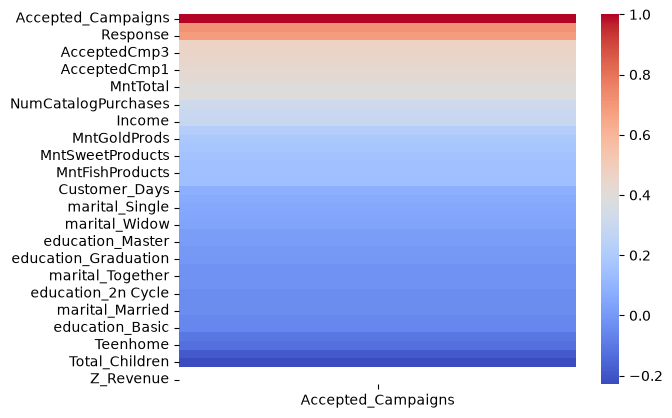

In [1110]:
corr = food.select_dtypes(include='number').corr(method='pearson')['Accepted_Campaigns'].sort_values(ascending=False) 
sns.heatmap(corr.to_frame(), cmap="coolwarm")

<Axes: >

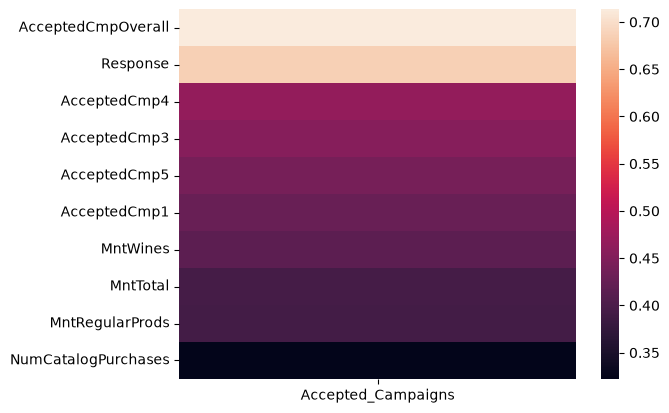

In [1111]:
all_correlations = corr

all_correlations = all_correlations[(all_correlations > 0.3) & (all_correlations < 1)]

sns.heatmap(all_correlations.to_frame())

In [1112]:
all_correlations

AcceptedCmpOverall     0.713352
Response               0.685109
AcceptedCmp4           0.465985
AcceptedCmp3           0.453742
AcceptedCmp5           0.441264
AcceptedCmp1           0.426687
MntWines               0.416651
MntTotal               0.393910
MntRegularProds        0.391931
NumCatalogPurchases    0.322143
Name: Accepted_Campaigns, dtype: float64

Age Distribution of Accepted Campaigns

In [1113]:
food['Age'].sort_values() 


1150    24
43      24
1824    25
727     25
2180    25
        ..
1897    77
341     77
398     77
407     79
1924    80
Name: Age, Length: 1843, dtype: int64

In [1114]:
age_groups = [(23,30), (31,40), (41,50), (51,60), (61,70), (71,85)]

def assign_age_group(age):
    for age_range in age_groups:
        if age_range[0] <= age <= age_range[1]:
            return f"{age_range[0]}-{age_range[1]}"
    return "Unknown"

food['Age_Group'] = food['Age'].apply(assign_age_group)

food.head()

,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Customer_Days,marital_Divorced,marital_Married,marital_Single,marital_Together,marital_Widow,education_2n Cycle,education_Basic,education_Graduation,education_Master,education_PhD,MntTotal,MntRegularProds,AcceptedCmpOverall,Total_Children,Marital_Status,Marital_Status_Label,Education_Level,Education_Level_Label,Accepted_Campaigns,Age_Group
0,58138.0,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,63,2822,0,0,3,0,0,0,0,3,0,0,1529,1441,0,0,3,Single,3,Graduation,1,61-70
1,46344.0,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,66,2272,0,0,3,0,0,0,0,3,0,0,21,15,0,2,3,Single,3,Graduation,0,61-70
2,71613.0,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,55,2471,0,0,0,2,0,0,0,3,0,0,734,692,0,0,2,Together,3,Graduation,0,51-60
3,26646.0,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,36,2298,0,0,0,2,0,0,0,3,0,0,48,43,0,1,2,Together,3,Graduation,0,31-40
4,58293.0,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,39,2320,0,4,0,0,0,0,0,0,0,5,407,392,0,1,4,Married,5,PhD,0,31-40


<Axes: xlabel='Age_Group', ylabel='Accepted_Campaigns'>

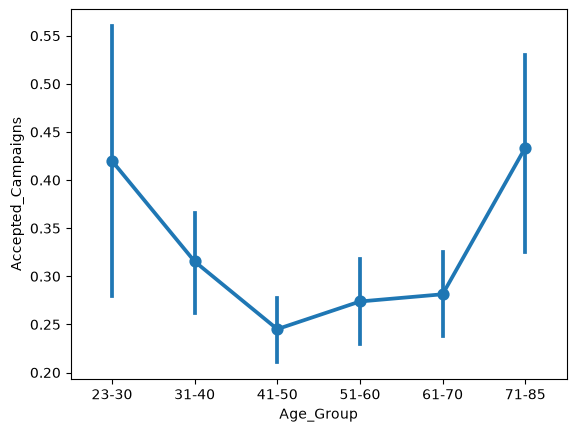

In [1115]:
age_order = [f"{age_range[0]}-{age_range[1]}" for age_range in age_groups]

sns.pointplot(x='Age_Group', y='Accepted_Campaigns', data=food, order=age_order)
# why point plot

In [1116]:
counts = food['Age_Group'].value_counts() # Count the number of occurrences of each age group

In [1117]:
percentage = counts / food.shape[0] # Calculate the percentage of each age group in the dataset

percent_food = percentage.reset_index() # Reset the index to convert the Series to a DataFrame

percent_food.columns = ['age_group', 'percentage'] # Rename the columns for clarity

percent_food = percent_food.sort_values('age_group')

percent_food

,age_group,percentage
5,23-30,0.027130
3,31-40,0.161693
0,41-50,0.332067
1,51-60,0.221921
2,61-70,0.212154
4,71-85,0.045035


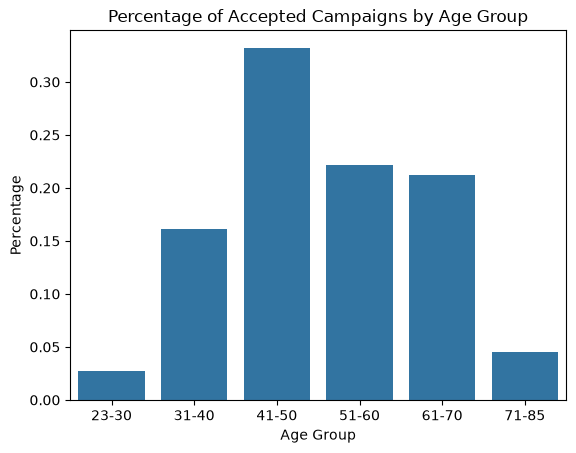

In [1118]:
sns.barplot(x='age_group', y='percentage', data=percent_food)
plt.title('Percentage of Accepted Campaigns by Age Group')
plt.ylabel('Percentage')
plt.xlabel('Age Group')
plt.show()

In [1119]:
# 31 to 70 are core audience


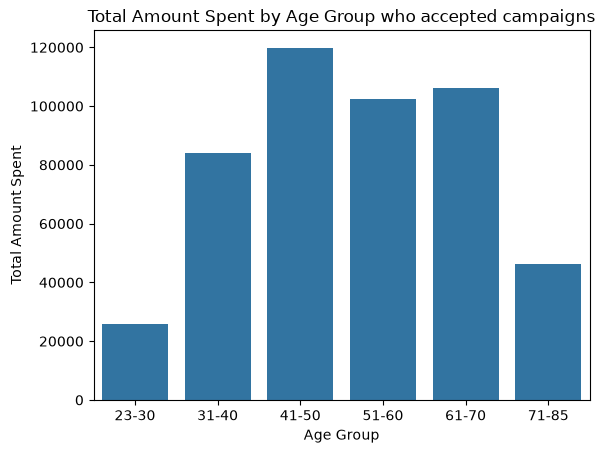

In [1120]:

# Filter the data to include only those who accepted campaigns
accept_camp = food[food['Accepted_Campaigns'] == 1]

grouped_food = accept_camp.groupby('Age_Group')['MntTotal'].sum().reset_index()

sns.barplot(x='Age_Group', y='MntTotal', data=grouped_food)
plt.title('Total Amount Spent by Age Group who accepted campaigns')
plt.ylabel('Total Amount Spent')
plt.xlabel('Age Group')
plt.show()

Purchases type

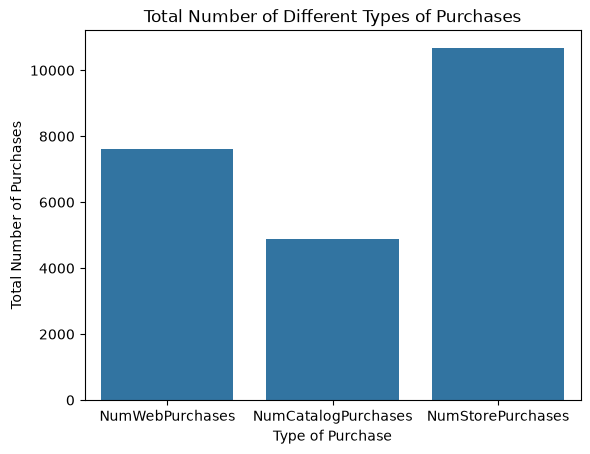

In [1121]:
# Sum of different types of purchases
sum_food = pd.DataFrame(food[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(), columns=['Sum']).reset_index()
sum_food.rename(columns={'index': 'Type_of_Purchase'}, inplace=True)


sns.barplot(x='Type_of_Purchase', y='Sum', data=sum_food)
plt.title('Total Number of Different Types of Purchases')
plt.ylabel('Total Number of Purchases')
plt.xlabel('Type of Purchase')
plt.show()

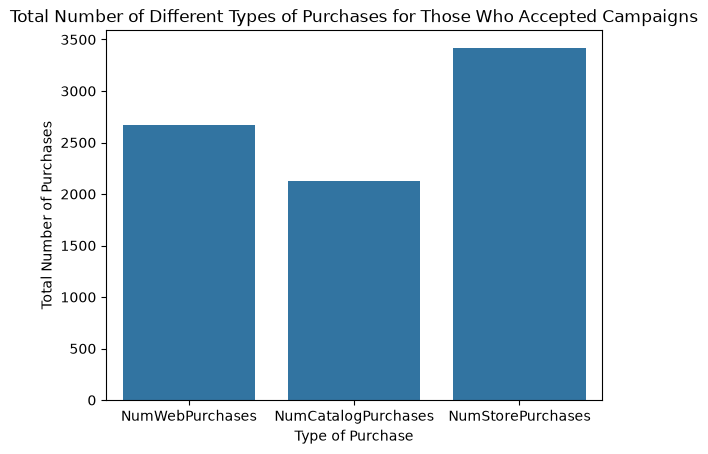

In [1122]:
# Sum of different types of purchases for those who accepted campaigns

sum_food = pd.DataFrame(accept_camp[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum(), columns=['Sum']).reset_index()
sum_food.rename(columns={'index': 'Type_of_Purchase'}, inplace=True)


sns.barplot(x='Type_of_Purchase', y='Sum', data=sum_food)
plt.title('Total Number of Different Types of Purchases for Those Who Accepted Campaigns')
plt.ylabel('Total Number of Purchases')
plt.xlabel('Type of Purchase')
plt.show()


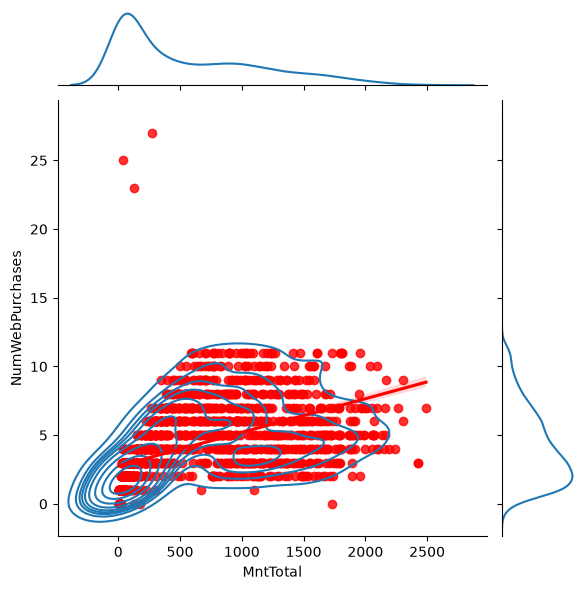

In [1123]:
x = sns.jointplot(data = food, x = 'MntTotal', y = 'NumWebPurchases', kind= 'kde' )
x.plot_joint(sns.regplot, color='r')

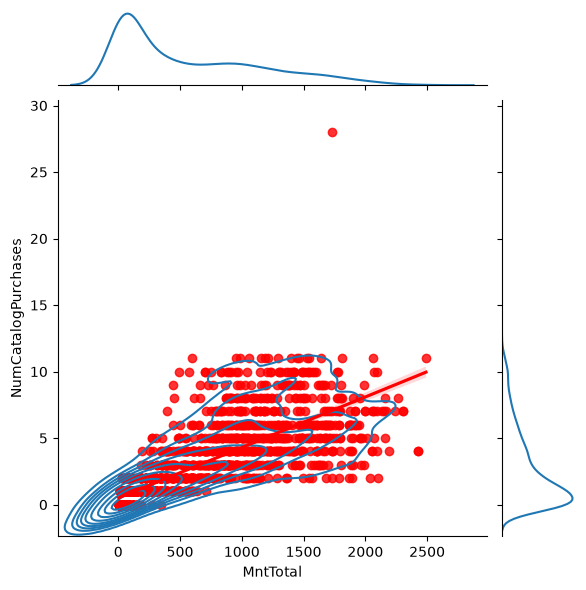

In [1124]:
x = sns.jointplot(data = food, x = 'MntTotal', y = 'NumCatalogPurchases', kind= 'kde' )
x.plot_joint(sns.regplot, color='r')

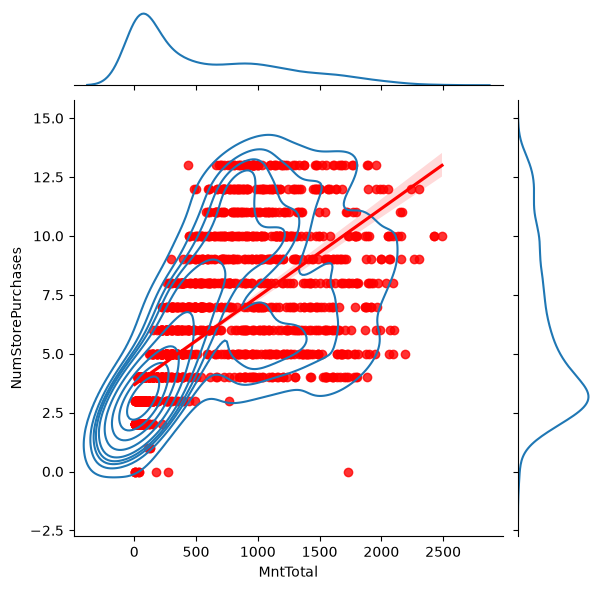

In [1125]:
x = sns.jointplot(data = food, x = 'MntTotal', y = 'NumStorePurchases', kind= 'kde' )
x.plot_joint(sns.regplot, color='r')

In [1126]:
# 2 directions: Boost up the higher percentage catalog customers. OR Focus on store/web purchases because they have more traffic

Children

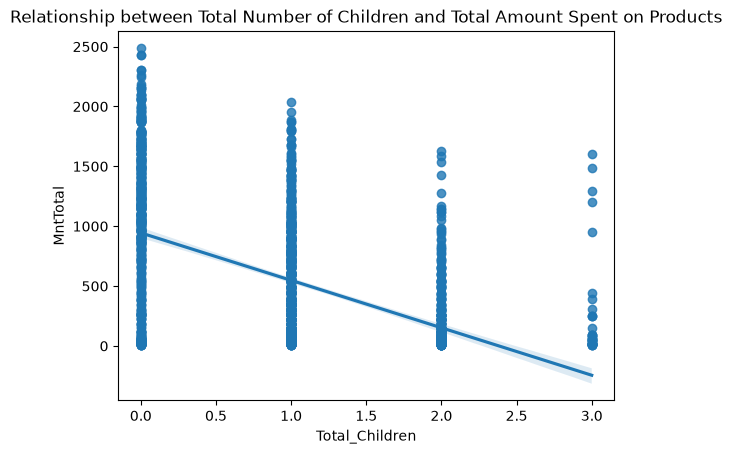

In [1127]:
# Relationship between total number of children in the household and total amount spent on products
sns.regplot(data = food, x = 'Total_Children', y = 'MntTotal')
plt.title('Relationship between Total Number of Children and Total Amount Spent on Products')
plt.show()

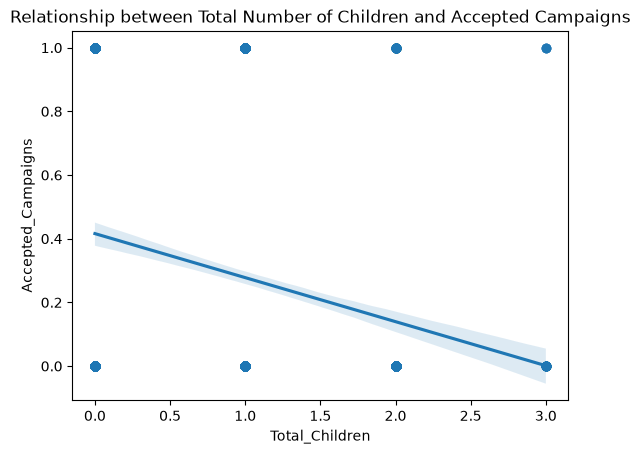

In [1128]:
# Relationship between total number of children in the household and accepted campaigns
sns.regplot(data = food, x = 'Total_Children', y = 'Accepted_Campaigns')
plt.title('Relationship between Total Number of Children and Accepted Campaigns')
plt.show()

# Less kids = higher likelihood of accepting campaigns

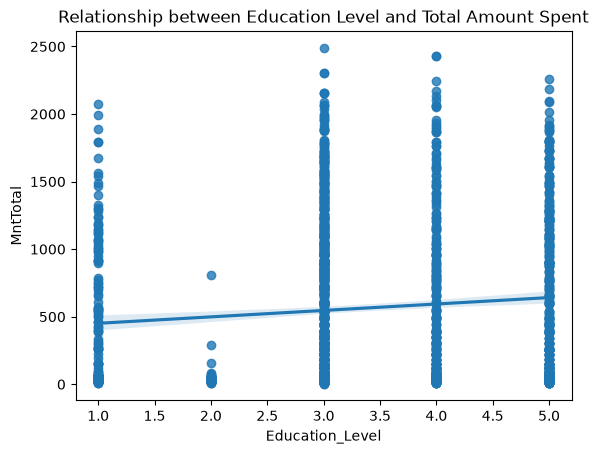

In [1129]:
# Relationship between education status and total amount spent

sns.regplot(data = food, x = 'Education_Level', y = 'MntTotal')
plt.title('Relationship between Education Level and Total Amount Spent')
plt.show()
# Higher education level = higher total amount spent but not a significant factor

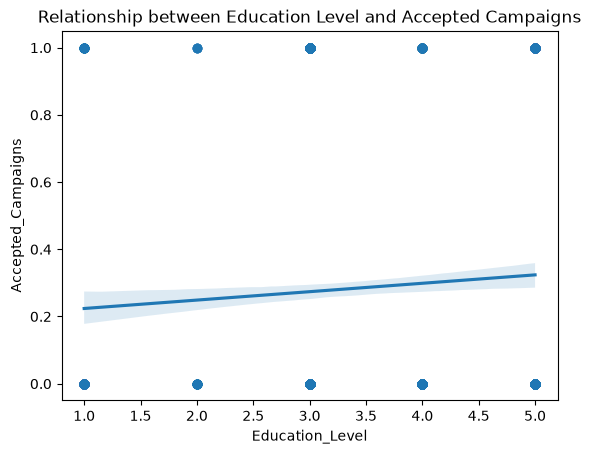

In [1130]:
# Relationship between education status and accepted campaigns

sns.regplot(data = food, x = 'Education_Level', y = 'Accepted_Campaigns')
plt.title('Relationship between Education Level and Accepted Campaigns')
plt.show()
# Higher education level = higher likelihood of accepting campaigns

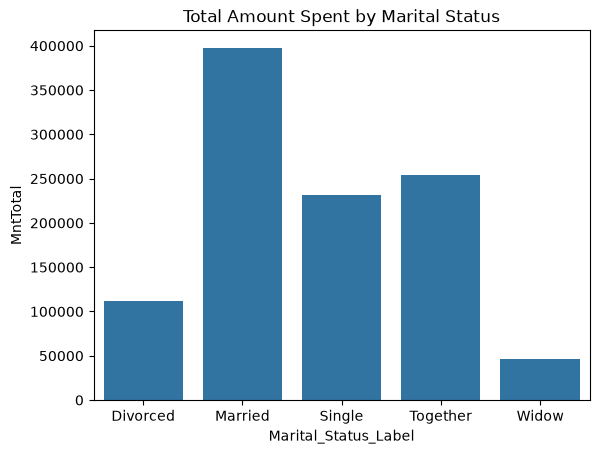

In [1131]:
relationship_food = food.groupby('Marital_Status_Label')['MntTotal'].sum().reset_index()
sns.barplot(data = relationship_food, x = 'Marital_Status_Label', y = 'MntTotal')
plt.title('Total Amount Spent by Marital Status')
plt.show()
# The bar plot shows the total amount spent by each marital status category

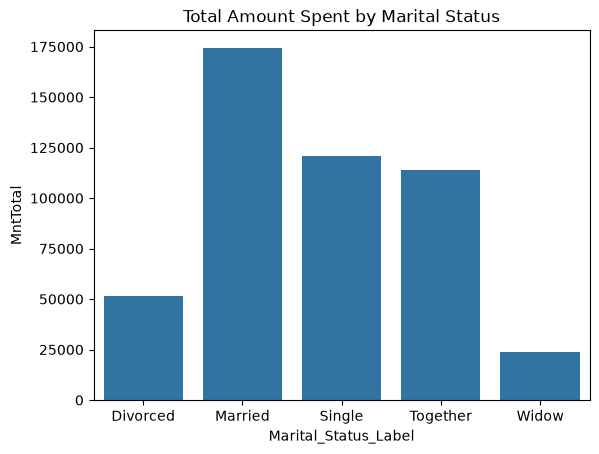

In [1132]:
accepted_relationship_food = accept_camp.groupby('Marital_Status_Label')['MntTotal'].sum().reset_index()
sns.barplot(data = accepted_relationship_food, x = 'Marital_Status_Label', y = 'MntTotal')
plt.title('Total Amount Spent by Marital Status')
plt.show()
# The bar plot shows the total amount spent by each marital status category for accepted campaigns

# married, single and together are speding more money compared to other marital status categories
# This insight can help target marketing campaigns more effectively towards these groups

In [1133]:
total = food['Marital_Status_Label'].value_counts() # Count of total campaigns by marital status
accepted = food[food['Accepted_Campaigns'] == 1]['Marital_Status_Label'].value_counts() # Count of accepted campaigns by marital status


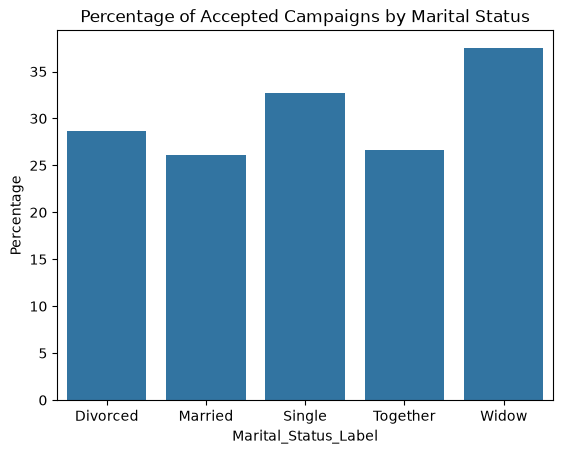

In [1134]:
percentage_marital = accepted/total *100
perct_food = percentage_marital.reset_index()
perct_food.columns = ['Marital_Status_Label', 'Percentage']

sns.barplot(data = perct_food, x = 'Marital_Status_Label', y = 'Percentage')
plt.title('Percentage of Accepted Campaigns by Marital Status')
plt.show()

OVERALL FINDINGS

1- Age: 30 -70 spending more money but less likely to accept campaigns
2- Purchase type: Catalog were more like to accept campaigns but in person spent more. Reccomend a split between all - 40% catalog 30% web 30% web
3- Chilldren:  less kids = more spending
4- Education: No impact dont target
5- Marital Status: doesnt play a big part: married sing and together spend more

Money making

 Middles aged People, high earners, with no kids. Target on diffrent platforms with split above

 New users to spend money
 Focus on 21-30, 70 and up, who statiscally accepted campagins at a higher rate
